# Which Test Next? Evidence-Aware Prediction Intervals for Cognitive Performance in Older Adults

**Research context:** Explainable and trustworthy AI for early dementia detection <br>
**Study type:** Independent pre-doctoral feasibility study <br>
**Data:** NHANES 2011–2014 cognitive functioning sample, adults aged 60 and over <br>

A prediction interval is only as honest as the data used to calibrate it. Risk tools are often calibrated where people have had most tests and then used where they have not. This notebook asks four questions with public data:

1. If 90% intervals are calibrated on people with complete evidence, what coverage do they give people assessed with less?
2. Does calibrating each evidence state separately, by masking the calibration set, restore coverage, including for people whose blood tests are genuinely missing?
3. Before a test is ordered, can we forecast how likely it is to settle a triage decision, and are those forecasts accurate once the result is revealed?
4. Is coverage equal across age, education, testing language and ethnicity?

Running the notebook from top to bottom downloads the NHANES files (about 90 MB), repeats every experiment over random splits and writes all figures to `figures/`. It takes about 12 minutes on a laptop.

## 1. Setup

In [1]:
import os
import platform
import time
import warnings
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import QuantileRegressor, RidgeCV
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)

CACHE = Path(os.environ.get("CACHE_DIR", Path.home() / ".cache" / "evidence_aware_uncertainty"))
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

ALPHA = 0.10            # 90% prediction intervals
THRESHOLD = -1.0        # low cognitive performance: composite below -1 SD
N_REPEATS = 200         # random train / calibration / test splits
N_BOOSTING = 50         # splits that also fit gradient boosting
N_VALUE = 60            # splits used for the value-of-the-next-test experiment
N_CQR = 100             # splits used for the quantile-regression robustness check
DRAWS = 200             # simulated test results per person
RANDOM_STATE = 2026

print(f"Python {platform.python_version()} | NumPy {np.__version__} | pandas {pd.__version__} | SciPy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {mpl.__version__}")

Python 3.13.9 | NumPy 2.5.4 | pandas 3.1.0 | SciPy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


In [2]:
# Figure style shared by every figure in the repository
FONT_URL = "https://raw.githubusercontent.com/octaviopardo/EBGaramond12/master/fonts/ttf/"
FONT_FILES = ("EBGaramond-Regular.ttf", "EBGaramond-Italic.ttf", "EBGaramond-Medium.ttf",
              "EBGaramond-SemiBold.ttf", "EBGaramond-Bold.ttf")

# Categorical colours checked for colour-vision deficiency on every pair (OKLab, Machado et al. 2009).
INK, INK_2, INK_3 = "#000000", "#000000", "#000000"
RULE, GRID, PAPER = "#000000", "#ECEEF1", "#FFFFFF"
NAVY, CRIMSON, TEAL, OCHRE, SLATE = "#2B5A9B", "#C0463E", "#139A84", "#D9962A", "#000000"
NAVY_PALE, CRIMSON_PALE = "#DCE6F3", "#F5DEDC"


def use_eb_garamond(cache_dir: Path) -> str:
    """Register EB Garamond (SIL Open Font Licence), downloading it once if needed."""
    cache_dir.mkdir(parents=True, exist_ok=True)
    for name in FONT_FILES:
        path = cache_dir / name
        if not path.exists():
            try:
                urlretrieve(FONT_URL + name, path)
            except OSError:
                continue
        font_manager.fontManager.addfont(str(path))
    family = "EB Garamond" if "EB Garamond" in {f.name for f in font_manager.fontManager.ttflist} else "serif"
    mpl.rcParams.update({
        "font.family": family, "font.size": 12.5,
        "mathtext.fontset": "custom", "mathtext.rm": family, "mathtext.it": f"{family}:italic",
        "mathtext.bf": f"{family}:semibold", "mathtext.cal": family, "mathtext.sf": family,
        "axes.labelsize": 13.5, "axes.labelcolor": INK_2, "axes.edgecolor": RULE, "axes.linewidth": 0.9,
        "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
        "grid.color": GRID, "grid.linewidth": 0.9,
        "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 12, "ytick.labelsize": 12,
        "xtick.major.width": 0.9, "ytick.major.width": 0.9,
        "legend.frameon": False, "legend.fontsize": 12,
        "figure.facecolor": PAPER, "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": PAPER,
    })
    return family


def new_figure(height: float = 6.0, width: float = 10.0):
    """One figure, one axis; a fixed width keeps every figure at the same scale in the README."""
    fig = plt.figure(figsize=(width, height))
    return fig, fig.add_axes([0.1, 0.15, 0.86, 0.65])


def frame(fig, ax, title, subtitle, note, left=0.1, right=0.96, top_pad=1.25, bottom_pad=1.15):
    """Fix the margins in inches, then write the title block and the source note."""
    w, h = fig.get_size_inches()
    ax.set_position([left, bottom_pad / h, right - left, 1 - (top_pad + bottom_pad) / h])
    fig.text(0.035, 1 - 0.42 / h, title, ha="left", va="baseline", fontsize=18.5, fontweight="semibold", color=INK)
    fig.text(0.035, 1 - 0.74 / h, subtitle, ha="left", va="baseline", fontsize=13.5, color=INK_2, style="italic")
    if note:
        fig.text(0.035, 0.2 / h, note, ha="left", va="baseline", fontsize=10.5, color=INK_3)


def save(fig, name: str):
    fig.savefig(FIG_DIR / name, dpi=300)
    plt.show()


def series_handle(colour, label, lw=2.0):
    return Line2D([], [], marker="o", ls="-", lw=lw, color=colour, markeredgecolor=PAPER, markersize=8, label=label)


FAMILY = use_eb_garamond(CACHE / "fonts")
print("Figure font:", FAMILY)

Figure font: EB Garamond


## 2. Data

The National Health and Nutrition Examination Survey (NHANES) gave three cognitive tests to participants aged 60 and over in the 2011–2012 and 2013–2014 cycles: the CERAD word-learning test with delayed recall, an animal fluency test and the Digit Symbol Substitution Test (Brody et al., 2019). The public files are downloaded from the CDC on first run.

The outcome is a composite: the mean of z-scored CERAD immediate recall (sum of three trials), CERAD delayed recall and the Digit Symbol Substitution Test, re-standardised to mean 0 and SD 1 in the analytic sample. *Low cognitive performance* is a composite below −1 SD. Animal fluency is kept out of the outcome because it plays the part of a brief test that could be given before a full assessment.

Two cohorts are formed. The **main cohort** has all three outcome tests, the fluency test and all seven blood markers, so any evidence can be hidden from them deliberately. The **real-missingness cohort** has the outcome and fluency tests but at least one blood marker genuinely missing; it is never used for fitting and serves as an external check.

In [3]:
# Download and merge the NHANES 2011-2012 and 2013-2014 components
NHANES_URL = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/{year}/DataFiles/{name}_{suffix}.xpt"
CYCLES = {"G": 2011, "H": 2013}
COMPONENTS = ("DEMO", "CFQ", "MCQ", "PFQ", "BPQ", "DIQ", "DPQ", "SMQ", "PAQ", "SLQ", "HUQ", "HIQ",
              "BMX", "BPX", "GHB", "TCHOL", "HDL", "BIOPRO", "CBC", "VID")


def read_xpt(path: Path) -> pd.DataFrame:
    """Read a SAS transport file; SAS stores exact zeros as 5.4e-79, so snap them back."""
    frame = pd.read_sas(path, format="xport", encoding="latin1")
    numeric = frame.select_dtypes("number").columns
    values = frame[numeric]
    frame[numeric] = values.mask(values.notna() & (values.abs() < 1e-20), 0.0)
    return frame


def load_nhanes(cache: Path) -> pd.DataFrame:
    """Merge every component on the respondent sequence number, keeping cognitive-test participants."""
    cache.mkdir(parents=True, exist_ok=True)
    cycles = []
    for suffix, year in CYCLES.items():
        tables = []
        for name in COMPONENTS:
            path = cache / f"{name}_{suffix}.xpt"
            if not path.exists():
                urlretrieve(NHANES_URL.format(year=year, name=name, suffix=suffix), path)
            tables.append(read_xpt(path).set_index("SEQN"))
        parts, seen = [], set()
        for table in [tables[1], tables[0]] + tables[2:]:
            keep = [c for c in table.columns if c not in seen]
            seen.update(keep)
            parts.append(table[keep])
        merged = pd.concat(parts, axis=1).loc[tables[1].index].copy()
        cycles.append(merged.reset_index().assign(cycle=f"{year}-{year + 1}"))
    return pd.concat(cycles, ignore_index=True)


raw = load_nhanes(CACHE / "nhanes")
print(f"Participants with a cognitive functioning record: {len(raw):,}")

Participants with a cognitive functioning record: 3,472


In [4]:
# Outcome, predictors and audit-only variables
def ckd_epi_2021(creatinine, age, female):
    """eGFR (mL/min/1.73 m2) from serum creatinine in mg/dL; CKD-EPI 2021, without race."""
    kappa = np.where(female, 0.7, 0.9)
    alpha = np.where(female, -0.241, -0.302)
    ratio = creatinine / kappa
    return 142 * np.minimum(ratio, 1) ** alpha * np.maximum(ratio, 1) ** -1.2 * 0.9938**age * np.where(female, 1.012, 1.0)


def build_cohort(raw: pd.DataFrame) -> pd.DataFrame:
    d = raw.copy()
    coded = lambda s, missing: s.where(~s.isin(missing))
    standard = lambda s: (s - s.mean()) / s.std(ddof=1)
    d["cerad_immediate"] = d[["CFDCST1", "CFDCST2", "CFDCST3"]].sum(axis=1, min_count=3)
    d = d[d[["cerad_immediate", "CFDCSR", "CFDDS"]].notna().all(axis=1)].copy()
    out = pd.DataFrame(index=d.index)
    out["seqn"] = d["SEQN"].astype(int)
    out["cycle"] = d["cycle"]
    out["cognition"] = standard((standard(d["cerad_immediate"]) + standard(d["CFDCSR"]) + standard(d["CFDDS"])) / 3)
    # Record: what a register or recruitment form would already hold
    out["age"] = d["RIDAGEYR"]
    out["female"] = (d["RIAGENDR"] == 2).astype(float)
    out["education"] = coded(d["DMDEDUC2"], [7, 9])
    out["income_ratio"] = d["INDFMPIR"]
    out["born_abroad"] = (coded(d["DMDBORN4"], [77, 99]) == 2).astype(float)
    out["spanish_testing"] = d["CFALANG"].isin([2, 3]).astype(float)
    out["partnered"] = coded(d["DMDMARTL"], [77, 99]).isin([1, 6]).astype(float)
    out["lives_alone"] = (d["DMDHHSIZ"] == 1).astype(float)
    out["insured"] = (d["HIQ011"] == 1).astype(float)
    # History: self-report that can be taken by telephone
    out["hypertension"] = (d["BPQ020"] == 1).astype(float)
    out["diabetes"] = d["DIQ010"].map({1: 1.0, 2: 0.0, 3: 0.5})
    out["heart_disease"] = ((d["MCQ160B"] == 1) | (d["MCQ160C"] == 1) | (d["MCQ160E"] == 1)).astype(float)
    out["stroke"] = (d["MCQ160F"] == 1).astype(float)
    out["phq9"] = d[[f"DPQ0{i}0" for i in range(1, 10)]].where(lambda v: v <= 3).sum(axis=1, min_count=7)
    out["ever_smoked"] = (d["SMQ020"] == 1).astype(float)
    out["current_smoker"] = d["SMQ040"].isin([1, 2]).astype(float)
    out["vigorous_activity"] = (d["PAQ650"] == 1).astype(float)
    out["moderate_activity"] = (d["PAQ665"] == 1).astype(float)
    out["sedentary_minutes"] = coded(d["PAD680"], [7777, 9999])
    out["sleep_hours"] = coded(d["SLD010H"], [77, 99])
    out["self_rated_health"] = coded(d["HUQ010"], [7, 9])
    out["memory_worse"] = (d["MCQ084"] == 1).astype(float)
    out["memory_limits"] = (d["PFQ057"] == 1).astype(float)
    # Examination and bloods: need a visit
    out["bmi"] = d["BMXBMI"]
    out["waist_cm"] = d["BMXWAIST"]
    out["systolic_bp"] = d[["BPXSY1", "BPXSY2", "BPXSY3", "BPXSY4"]].replace(0, np.nan).mean(axis=1)
    out["diastolic_bp"] = d[["BPXDI1", "BPXDI2", "BPXDI3", "BPXDI4"]].replace(0, np.nan).mean(axis=1)
    out["hba1c"] = d["LBXGH"]
    out["total_cholesterol"] = d["LBXTC"]
    out["hdl_cholesterol"] = d["LBDHDD"]
    out["albumin"] = d["LBXSAL"]
    out["haemoglobin"] = d["LBXHGB"]
    out["vitamin_d"] = d["LBXVIDMS"]
    out["egfr"] = ckd_epi_2021(d["LBXSCR"], d["RIDAGEYR"], out["female"] == 1)
    # The one-minute test
    out["animal_fluency"] = d["CFDAST"]
    # Audit-only variables, never used as predictors, and the examination weight
    out["ethnicity"] = d["RIDRETH3"].map({1: "Mexican American", 2: "Other Hispanic", 3: "Non-Hispanic White",
                                          4: "Non-Hispanic Black", 6: "Non-Hispanic Asian", 7: "Other or multiple"})
    out["mec_weight"] = d["WTMEC2YR"] / 2
    return out.reset_index(drop=True)


BLOOD_MARKERS = ["hba1c", "total_cholesterol", "hdl_cholesterol", "albumin", "haemoglobin", "vitamin_d", "egfr"]
cohort = build_cohort(raw)
blood_missing = cohort[BLOOD_MARKERS].isna().any(axis=1)
main = cohort[~blood_missing & cohort.animal_fluency.notna()].reset_index(drop=True)
real = cohort[blood_missing & cohort.animal_fluency.notna()].reset_index(drop=True)

summary = pd.DataFrame({
    "Main cohort": [len(main), main.age.mean(), main.female.mean(), (main.education <= 2).mean(),
                    main.spanish_testing.mean(), (main.cognition < THRESHOLD).mean(), main.cognition.mean()],
    "Bloods genuinely missing": [len(real), real.age.mean(), real.female.mean(), (real.education <= 2).mean(),
                                 real.spanish_testing.mean(), (real.cognition < THRESHOLD).mean(), real.cognition.mean()],
}, index=["Participants", "Mean age (years)", "Women", "Did not finish high school", "Tested in Spanish",
          "Composite below -1 SD", "Mean composite (SD units)"])
display(summary.round(3))

,Main cohort,Bloods genuinely missing
Participants,2760.000,174.000
Mean age (years),69.472,69.621
Women,0.509,0.586
Did not finish high school,0.249,0.333
Tested in Spanish,0.119,0.103
Composite below -1 SD,0.161,0.253
Mean composite (SD units),0.027,-0.253


## 3. Evidence states

Four blocks of evidence are nested into six states, from age and sex alone to everything. *History* is what a clinician could take by telephone. *Bloods* stands for the examination and blood panel that need a visit. *Fluency* is the number of animals named in one minute, a test that can also be given by telephone. Race and ethnicity are never used as predictors; they are kept only to audit coverage.

In [5]:
# Six nested evidence states
RECORD = ["age", "female", "education", "income_ratio", "born_abroad", "spanish_testing",
          "partnered", "lives_alone", "insured"]
HISTORY = ["hypertension", "diabetes", "heart_disease", "stroke", "phq9", "ever_smoked", "current_smoker",
           "vigorous_activity", "moderate_activity", "sedentary_minutes", "sleep_hours", "self_rated_health",
           "memory_worse", "memory_limits"]
EXAM_BLOODS = ["bmi", "waist_cm", "systolic_bp", "diastolic_bp"] + BLOOD_MARKERS
FLUENCY = ["animal_fluency"]

STATES = {
    "Age and sex": ["age", "female"],
    "Record": RECORD,
    "History": RECORD + HISTORY,
    "History + bloods": RECORD + HISTORY + EXAM_BLOODS,
    "History + fluency": RECORD + HISTORY + FLUENCY,
    "Complete": RECORD + HISTORY + EXAM_BLOODS + FLUENCY,
}
NAMES = list(STATES)
display(pd.DataFrame({"Predictors": {s: len(c) for s, c in STATES.items()}}))

,Predictors
Age and sex,2
Record,9
History,23
History + bloods,34
History + fluency,24
Complete,35


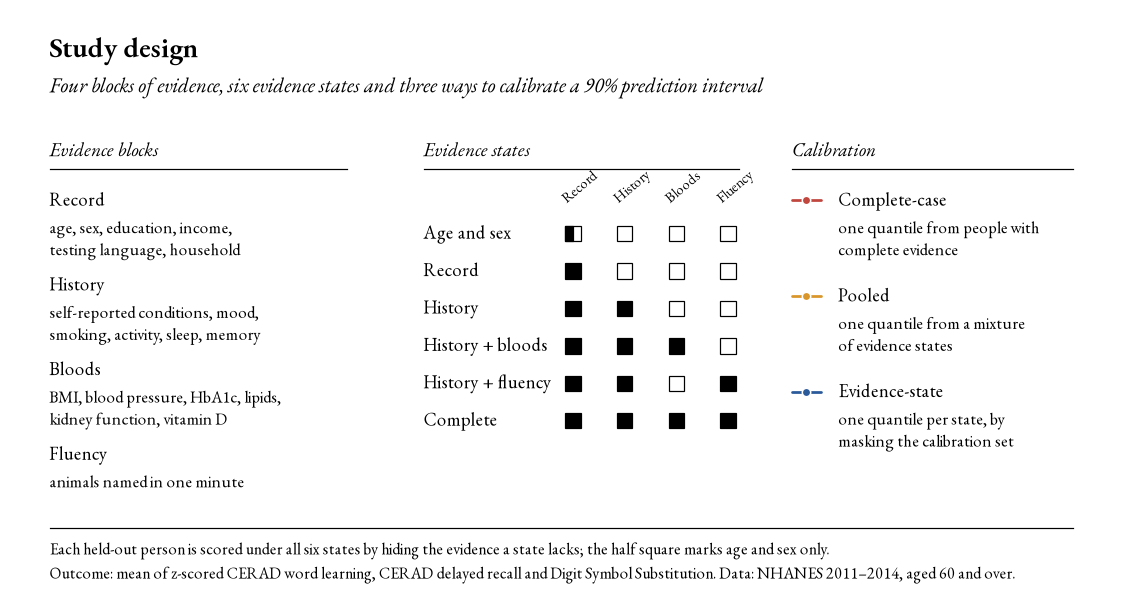

In [6]:
# Figure 1: study design
FILL, HAIR = "#000000", "#000000"
BLOCK_NOTES = [("Record", "age, sex, education, income,\ntesting language, household"),
               ("History", "self-reported conditions, mood,\nsmoking, activity, sleep, memory"),
               ("Bloods", "BMI, blood pressure, HbA1c, lipids,\nkidney function, vitamin D"),
               ("Fluency", "animals named in one minute")]
MASKS = [[0.5, 0, 0, 0], [1, 0, 0, 0], [1, 1, 0, 0], [1, 1, 1, 0], [1, 1, 0, 1], [1, 1, 1, 1]]
SCHEMES = [("Complete-case", "one quantile from people with\ncomplete evidence", CRIMSON),
           ("Pooled", "one quantile from a mixture\nof evidence states", OCHRE),
           ("Evidence-state", "one quantile per state, by\nmasking the calibration set", NAVY)]

W, H = 10.0, 5.4
fig = plt.figure(figsize=(W, H))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W)
ax.set_ylim(H, 0)          # positions in inches from the top
ax.axis("off")


def text(x, y, s, size=12, color=INK, **kw):
    return ax.text(x, y, s, fontsize=size, color=color, ha=kw.pop("ha", "left"), va=kw.pop("va", "baseline"), **kw)


def lines(x, y, body, size=10.8, color=INK_3, step=0.2):
    """Draw each line on its own baseline so that neighbouring columns line up exactly."""
    for k, line in enumerate(body.split("\n")):
        text(x, y + k * step, line, size=size, color=color)


text(0.35, 0.42, "Study design", size=18.5, fontweight="semibold")
text(0.35, 0.74, "Four blocks of evidence, six evidence states and three ways to calibrate a 90% prediction interval",
     size=13.5, color=INK_2, style="italic")
HEAD = 1.32
for x0, x1, name in [(0.35, 3.05, "Evidence blocks"), (3.75, 6.62, "Evidence states"), (7.1, 9.65, "Calibration")]:
    text(x0, HEAD, name, size=12.5, color=INK_2, style="italic")
    ax.plot([x0, x1], [HEAD + 0.12, HEAD + 0.12], color=HAIR, lw=0.8)
TOP = HEAD + 0.45

y = TOP
for name, note in BLOCK_NOTES:
    text(0.35, y, name)
    lines(0.35, y + 0.25, note)
    y += 0.25 + 0.2 * (note.count("\n") + 1) + 0.12

col_x = [5.05 + i * 0.47 for i in range(4)]
for cx, (name, _) in zip(col_x, BLOCK_NOTES):
    text(cx, TOP - 0.02, name, size=9.5, color=INK_3, rotation=40, rotation_mode="anchor")
s = 0.14
for i, (name, mask) in enumerate(zip(NAMES, MASKS)):
    yy = TOP + 0.3 + i * 0.34
    text(3.75, yy, name)
    for cx, m in zip(col_x, mask):
        corner = (cx - s / 2 + 0.06, yy - 0.115)
        ax.add_patch(Rectangle(corner, s, s, facecolor=FILL if m == 1 else PAPER, edgecolor=FILL if m == 1 else HAIR, lw=0.8))
        if m == 0.5:
            ax.add_patch(Rectangle(corner, s / 2, s, facecolor=FILL, edgecolor=FILL, lw=0.8))

y = TOP
for name, note, colour in SCHEMES:
    ax.plot([7.1, 7.36], [y - 0.05, y - 0.05], color=colour, lw=1.8, solid_capstyle="round")
    ax.plot(7.23, y - 0.05, "o", color=colour, markersize=5.5, markeredgecolor=PAPER, markeredgewidth=1.0)
    text(7.52, y, name)
    lines(7.52, y + 0.25, note)
    y += 0.25 + 0.4 + 0.22

ax.plot([0.35, 9.65], [4.7, 4.7], color=HAIR, lw=0.8)
text(0.35, 4.94, "Each held-out person is scored under all six states by hiding the evidence a state lacks; the half square marks age and sex only.",
     size=10.5, color=INK_3)
text(0.35, 5.16, "Outcome: mean of z-scored CERAD word learning, CERAD delayed recall and Digit Symbol Substitution. Data: NHANES 2011–2014, aged 60 and over.",
     size=10.5, color=INK_3)
save(fig, "01_study_design.png")

## 4. Methods

**Models.** For each evidence state $s$ a ridge regression $\hat\mu_s(x)$ is fitted on the training split, with median imputation and missingness indicators for the few values missing inside a block. Gradient boosting is fitted on the first 50 splits as a non-linear comparison.

**Split conformal intervals.** With absolute residuals $R_i = |Y_i - \hat\mu_s(X_i)|$ on a calibration set of size $n$, the interval is $\hat\mu_s(x) \pm \hat q$, where $\hat q$ is the $\lceil (n+1)(1-\alpha) \rceil$-th smallest residual (Vovk et al., 2005; Lei et al., 2018). The three schemes differ only in which residuals enter $\hat q$:

| Scheme | Residuals used for $\hat q$ |
|---|---|
| Complete-case | residuals of the complete-evidence model, applied to every state |
| Pooled | one draw per calibration person from a deployment mix (History 55%, History + bloods 20%, History + fluency 15%, Complete 10%) |
| Evidence-state | residuals of the state-$s$ model on the whole calibration set, which is possible because evidence can be hidden from anyone who has it |

The evidence-state scheme is a Mondrian conformal predictor whose categories are evidence patterns (Vovk et al., 2005), and it is close to the missing-data augmentation of Zaffran et al. (2023). If prediction errors were Gaussian with spread $\sigma_s$ under state $s$, an interval calibrated on complete evidence would cover with probability

$$
\mathrm{coverage}_s \approx 2\Phi\!\left(\frac{z_{1-\alpha/2}}{\rho_s}\right) - 1, \qquad \rho_s = \frac{\sigma_s}{\sigma_{\mathrm{complete}}}.
$$

**Triage and the value of the next test.** A person is *ruled out* when the whole interval lies above −1 SD, *flagged* when it lies below, and *undecided* otherwise. For someone undecided on history alone, the probability that a test settles the decision is forecast by simulating the missing result 200 times from a ridge model of that result given history, with residuals resampled jointly from the training data, and passing each simulated result through the state model. The forecast is then compared with what happens when the real result, hidden until then, is revealed.

**Validation.** Each of 200 random splits uses half the main cohort for training, a quarter for calibration and a quarter for testing. Every person in the test quarter is scored under every evidence state.

In [7]:
# Models, conformal quantile and triage rule
def ridge_model():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         RidgeCV(alphas=np.logspace(-2, 3, 30)))


def boosting_model():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.04, max_leaf_nodes=15,
                                         min_samples_leaf=30, l2_regularization=1.0, random_state=0)


def quantile_model(q):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         QuantileRegressor(quantile=q, alpha=0.001, solver="highs"))


def conformal_quantile(scores: np.ndarray, alpha: float = ALPHA) -> float:
    """The ceil((n+1)(1-alpha))-th smallest score, or infinity when the calibration set is too small."""
    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    return np.inf if k > n else float(np.sort(scores)[k - 1])


def triage(mu, q):
    return np.where(mu - q > THRESHOLD, "rule-out", np.where(mu + q < THRESHOLD, "flag", "uncertain"))


MIX = {"Age and sex": 0.0, "Record": 0.0, "History": 0.55, "History + bloods": 0.20,
       "History + fluency": 0.15, "Complete": 0.10}

In [8]:
# Repeated-split experiment
def simulate_value(tr, te, models, q, mu_te, before, rng):
    """Forecast, then reveal, whether fluency or bloods would settle each undecided triage decision."""
    history = STATES["History"]
    prep = models["History"][:-1]
    z_tr, z_te = prep.transform(tr[history]), prep.transform(te[history])
    rows = []
    for test, block, state in [("Fluency", FLUENCY, "History + fluency"), ("Bloods", EXAM_BLOODS, "History + bloods")]:
        observed = tr[block].fillna(tr[block].median()).to_numpy()
        conditional = RidgeCV(alphas=np.logspace(-2, 3, 30)).fit(z_tr, observed)
        resid = observed - conditional.predict(z_tr).reshape(observed.shape)
        centre = conditional.predict(z_te).reshape(len(te), -1)
        draws = centre[:, None, :] + resid[rng.integers(0, len(resid), size=(len(te), DRAWS))]
        neighbours = observed[NearestNeighbors(n_neighbors=50).fit(z_tr).kneighbors(z_te, return_distance=False)]
        x = te[STATES[state]].reset_index(drop=True)
        forecast = {}
        for method, sims in [("regression", draws), ("neighbours", neighbours)]:
            k = sims.shape[1]
            if test == "Fluency":
                sims = np.clip(np.round(sims), 0, None)
            xx = x.loc[np.repeat(np.arange(len(x)), k)].reset_index(drop=True)
            xx[block] = sims.reshape(-1, len(block))
            forecast[method] = (triage(models[state].predict(xx).reshape(len(x), k), q[state]) != "uncertain").mean(axis=1)
        rows.append(pd.DataFrame({
            "test": test, "row": te.index, "before": before, "after": triage(mu_te[state], q[state]),
            "p_regression": forecast["regression"], "p_neighbours": forecast["neighbours"], "y": te.cognition.to_numpy(),
            "lo_before": mu_te["History"] - q["History"], "hi_before": mu_te["History"] + q["History"],
            "lo_after": mu_te[state] - q[state], "hi_after": mu_te[state] + q[state]}))
    return pd.concat(rows, ignore_index=True)


rng = np.random.default_rng(RANDOM_STATE)
splits = []
for _ in range(N_REPEATS):
    order = rng.permutation(len(main))
    n_train, n_cal = len(main) // 2, len(main) // 4
    splits.append((order[:n_train], order[n_train:n_train + n_cal], order[n_train + n_cal:]))

perf, cover, person, real_hits, value, cqr = [], [], [], [], [], []
start = time.time()
for rep, (i_tr, i_ca, i_te) in enumerate(splits):
    tr, ca, te = main.iloc[i_tr], main.iloc[i_ca], main.iloc[i_te]
    y_ca, y_te = ca.cognition.to_numpy(), te.cognition.to_numpy()
    models, q, rmse, res_ca, mu_te = {}, {}, {}, {}, {}
    for s, cols in STATES.items():
        models[s] = ridge_model().fit(tr[cols], tr.cognition)
        pred_ca = models[s].predict(ca[cols])
        res_ca[s] = np.abs(y_ca - pred_ca)
        q[s] = conformal_quantile(res_ca[s])
        rmse[s] = np.sqrt(np.mean((y_ca - pred_ca) ** 2))
        mu_te[s] = models[s].predict(te[cols])
        perf.append({"rep": rep, "state": s, "model": "Ridge regression",
                     "r2": 1 - np.mean((y_te - mu_te[s]) ** 2) / np.var(y_te), "mae": np.mean(np.abs(y_te - mu_te[s]))})
        if rep < N_BOOSTING:
            pb = boosting_model().fit(tr[cols], tr.cognition).predict(te[cols])
            perf.append({"rep": rep, "state": s, "model": "Gradient boosting",
                         "r2": 1 - np.mean((y_te - pb) ** 2) / np.var(y_te), "mae": np.mean(np.abs(y_te - pb))})
    mixed = rng.choice(NAMES, size=len(ca), p=[MIX[s] for s in NAMES])
    q_pooled = conformal_quantile(np.array([res_ca[s][k] for k, s in enumerate(mixed)]))
    for s in NAMES:
        schemes = {"Complete-case": q["Complete"], "Pooled": q_pooled, "Evidence-state": q[s]}
        for scheme, qq in schemes.items():
            hit = np.abs(y_te - mu_te[s]) <= qq
            cover.append({"rep": rep, "state": s, "scheme": scheme, "coverage": hit.mean(), "width": 2 * qq,
                          "sd_ratio": rmse[s] / rmse["Complete"]})
        if s in ("History", "Complete"):
            person.append(pd.DataFrame({"rep": rep, "row": i_te, "state": s,
                                        "hit": np.abs(y_te - mu_te[s]) <= q[s]}))
    for s in ("History", "History + fluency"):
        hit = np.abs(real.cognition.to_numpy() - models[s].predict(real[STATES[s]])) <= q[s]
        real_hits.append(pd.DataFrame({"rep": rep, "row": np.arange(len(real)), "state": s, "hit": hit}))
    if rep < N_VALUE:
        value.append(simulate_value(tr, te, models, q, mu_te, triage(mu_te["History"], q["History"]), rng).assign(rep=rep))
    if rep < N_CQR:
        scores, bands = {}, {}
        for s, cols in STATES.items():
            lo = quantile_model(ALPHA / 2).fit(tr[cols], tr.cognition)
            hi = quantile_model(1 - ALPHA / 2).fit(tr[cols], tr.cognition)
            scores[s] = np.maximum(lo.predict(ca[cols]) - y_ca, y_ca - hi.predict(ca[cols]))
            bands[s] = (lo.predict(te[cols]), hi.predict(te[cols]))
        for s in NAMES:
            lo_t, hi_t = bands[s]
            for scheme, qq in [("Complete-case", conformal_quantile(scores["Complete"])), ("Evidence-state", conformal_quantile(scores[s]))]:
                cqr.append({"rep": rep, "state": s, "scheme": scheme,
                            "coverage": np.mean((y_te >= lo_t - qq) & (y_te <= hi_t + qq)), "width": np.mean(hi_t - lo_t + 2 * qq)})
    if rep % 50 == 0:
        print(f"split {rep:3d}  elapsed {time.time() - start:6.0f} s")

perf, cover, cqr = pd.DataFrame(perf), pd.DataFrame(cover), pd.DataFrame(cqr)
person = pd.concat(person, ignore_index=True)
real_hits = pd.concat(real_hits, ignore_index=True)
value = pd.concat(value, ignore_index=True)
print(f"Finished {N_REPEATS} splits in {time.time() - start:.0f} s")

split   0  elapsed     10 s


split  50  elapsed    704 s


split 100  elapsed    769 s


split 150  elapsed    771 s


Finished 200 splits in 773 s


## 5. Results

### 5.1 How much each kind of evidence explains

mean                               2.5%  \
model             Gradient boosting Ridge regression Gradient boosting   
state                                                                    
Age and sex                   0.120            0.143             0.070   
Record                        0.292            0.351             0.230   
History                       0.369            0.399             0.317   
History + bloods              0.365            0.408             0.307   
History + fluency             0.452            0.476             0.401   
Complete                      0.447            0.479             0.398   

                                               97.5%                   
model             Ridge regression Gradient boosting Ridge regression  
state                                                                  
Age and sex                  0.104             0.158            0.177  
Record                       0.303             0.357            0.395  
History                      0.346             0.434            0.443  
History + bloods             0.355             0.431            0.458  
History + fluency            0.433             0.509            0.519  
Complete                     0.438             0.502            0.528

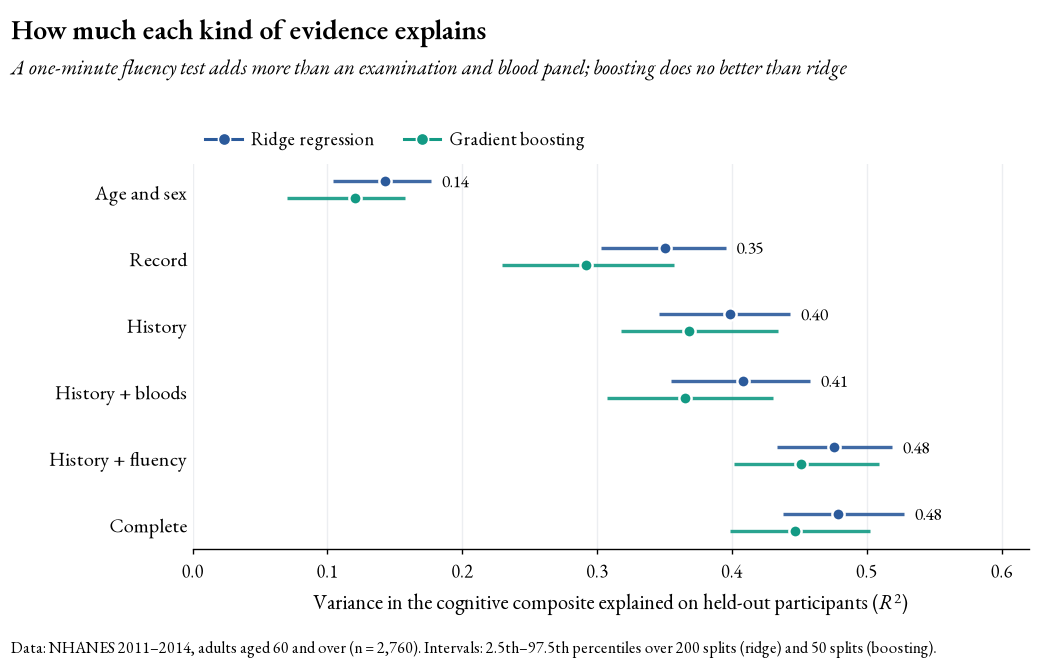

In [9]:
# Explained variance by evidence state and model
def interval(s):
    return pd.Series({"mean": s.mean(), "2.5%": s.quantile(0.025), "97.5%": s.quantile(0.975)})


r2_table = perf.groupby(["state", "model"]).r2.apply(interval).unstack().unstack("model").reindex(NAMES)
display(r2_table.round(3))

fig, ax = new_figure(6.2)
y = np.arange(len(NAMES))
for off, model, colour in [(-0.13, "Ridge regression", NAVY), (0.13, "Gradient boosting", TEAL)]:
    g = perf[perf.model == model].groupby("state").r2
    mid, lo, hi = (g.mean().reindex(NAMES), g.quantile(0.025).reindex(NAMES), g.quantile(0.975).reindex(NAMES))
    ax.hlines(y + off, lo, hi, color=colour, lw=2.2, alpha=0.9, zorder=2)
    ax.scatter(mid, y + off, s=64, color=colour, edgecolor=PAPER, linewidth=1.6, zorder=3)
    if model == "Ridge regression":
        for yy, m, h in zip(y, mid, hi):
            ax.text(h + 0.008, yy + off, f"{m:.2f}", va="center", ha="left", fontsize=11.5, color=INK_2)
ax.set_yticks(y, NAMES)
ax.tick_params(axis="y", length=0, labelsize=13, labelcolor=INK)
ax.spines["left"].set_visible(False)
ax.invert_yaxis()
ax.grid(axis="x")
ax.set_xlim(0, 0.62)
ax.set_xlabel("Variance in the cognitive composite explained on held-out participants ($R^2$)")
ax.legend(handles=[series_handle(NAVY, "Ridge regression"), series_handle(TEAL, "Gradient boosting")],
          loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2, columnspacing=1.6, handletextpad=0.5, borderaxespad=0.3)
frame(fig, ax, "How much each kind of evidence explains",
      "A one-minute fluency test adds more than an examination and blood panel; boosting does no better than ridge",
      "Data: NHANES 2011–2014, adults aged 60 and over (n = 2,760). Intervals: 2.5th–97.5th percentiles over 200 splits (ridge) and 50 splits (boosting).",
      left=0.2, top_pad=1.55)
save(fig, "02_evidence_and_explained_variance.png")

### 5.2 Coverage when calibration and deployment evidence differ

The shaded band is the range that test-set coverage should fall in, across splits, if the interval is valid. Under exchangeability the conditional coverage of a split-conformal interval follows a beta distribution with parameters $k = \lceil (n+1)(1-\alpha) \rceil$ and $n + 1 - k$ (Vovk, 2012), and the band adds binomial noise for the finite test set.

coverage                               width  \
scheme            Complete-case Evidence-state Pooled Complete-case   
state                                                                 
Age and sex               0.799          0.901  0.823          2.36   
Record                    0.865          0.902  0.885          2.36   
History                   0.874          0.902  0.896          2.36   
History + bloods          0.876          0.901  0.897          2.36   
History + fluency         0.897          0.901  0.916          2.36   
Complete                  0.902          0.902  0.919          2.36   

                                         
scheme            Evidence-state Pooled  
state                                    
Age and sex                3.026  2.491  
Record                     2.621  2.491  
History                    2.529  2.491  
History + bloods           2.516  2.491  
History + fluency          2.386  2.491  
Complete                   2.360  2.491

Expected spread of test coverage under valid calibration: 0.867 to 0.930


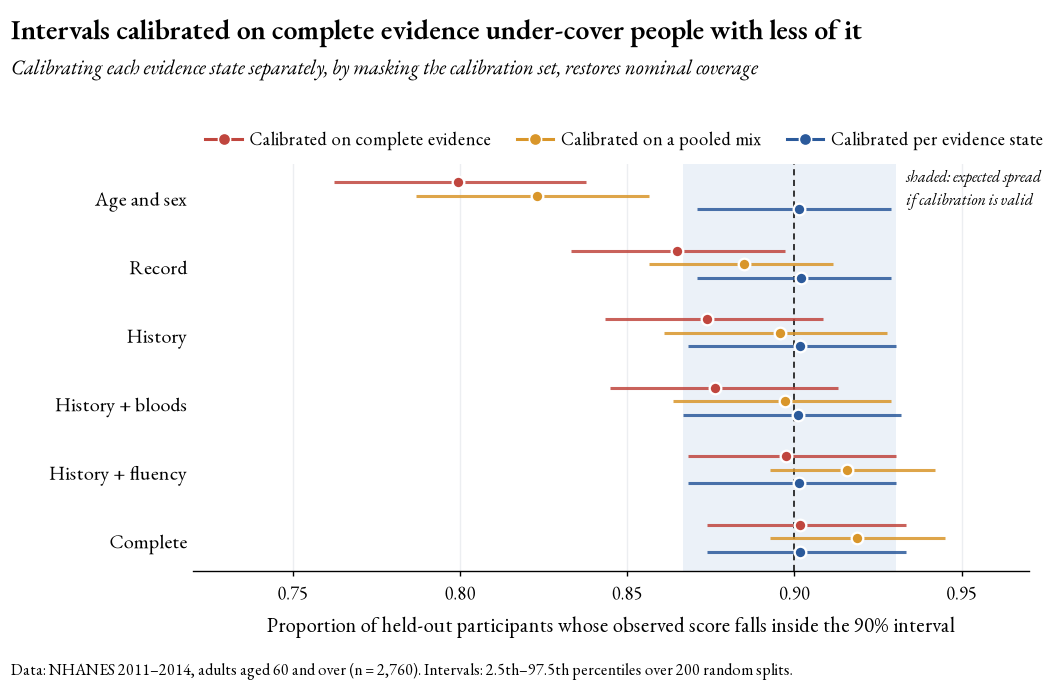

In [10]:
# Coverage under the three calibration schemes
def beta_band(n_cal, n_test, alpha=ALPHA, draws=200_000, seed=0):
    rng_band = np.random.default_rng(seed)
    k = int(np.ceil((n_cal + 1) * (1 - alpha)))
    conditional = rng_band.beta(k, n_cal + 1 - k, draws)
    return np.quantile(rng_band.binomial(n_test, conditional) / n_test, [0.025, 0.975])


coverage_table = (cover.groupby(["scheme", "state"]).agg(coverage=("coverage", "mean"), width=("width", "mean"))
                  .unstack("scheme").reindex(NAMES))
display(coverage_table.round(3))

n_cal, n_test = len(splits[0][1]), len(splits[0][2])
band = beta_band(n_cal, n_test)
print(f"Expected spread of test coverage under valid calibration: {band[0]:.3f} to {band[1]:.3f}")

fig, ax = new_figure(6.4)
y = np.arange(len(NAMES))
ax.axvspan(*band, color=NAVY_PALE, alpha=0.55, lw=0, zorder=0)
ax.axvline(1 - ALPHA, color=INK_3, lw=1.0, ls=(0, (4, 3)), zorder=1)
for scheme, colour, off in [("Complete-case", CRIMSON, -0.2), ("Pooled", OCHRE, 0.0), ("Evidence-state", NAVY, 0.2)]:
    g = cover[cover.scheme == scheme].groupby("state").coverage
    ax.hlines(y + off, g.quantile(0.025).reindex(NAMES), g.quantile(0.975).reindex(NAMES), color=colour, lw=2.0, alpha=0.85, zorder=2)
    ax.scatter(g.mean().reindex(NAMES), y + off, s=58, color=colour, edgecolor=PAPER, linewidth=1.5, zorder=3)
ax.set_yticks(y, NAMES)
ax.tick_params(axis="y", length=0, labelsize=13, labelcolor=INK)
ax.spines["left"].set_visible(False)
ax.invert_yaxis()
ax.grid(axis="x")
ax.set_xlim(0.72, 0.97)
ax.set_xlabel("Proportion of held-out participants whose observed score falls inside the 90% interval")
ax.legend(handles=[series_handle(CRIMSON, "Calibrated on complete evidence"), series_handle(OCHRE, "Calibrated on a pooled mix"),
                   series_handle(NAVY, "Calibrated per evidence state")],
          loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=3, columnspacing=1.4, handletextpad=0.4, borderaxespad=0.3)
ax.text(band[1] + 0.003, -0.42, "shaded: expected spread\nif calibration is valid", fontsize=10.5, color=INK_3,
        va="top", ha="left", style="italic", linespacing=1.1)
frame(fig, ax, "Intervals calibrated on complete evidence under-cover people with less of it",
      "Calibrating each evidence state separately, by masking the calibration set, restores nominal coverage",
      "Data: NHANES 2011–2014, adults aged 60 and over (n = 2,760). Intervals: 2.5th–97.5th percentiles over 200 random splits.",
      left=0.2, top_pad=1.55)
save(fig, "03_coverage_by_calibration_scheme.png")

### 5.3 The size of the loss is predictable

,sd_ratio,predicted,observed
state,,,
Age and sex,1.282,0.801,0.799
Record,1.118,0.859,0.865
History,1.074,0.874,0.874
History + bloods,1.065,0.878,0.876
History + fluency,1.004,0.899,0.897
Complete,1.000,0.900,0.902


Largest gap between predicted and observed coverage: 0.006


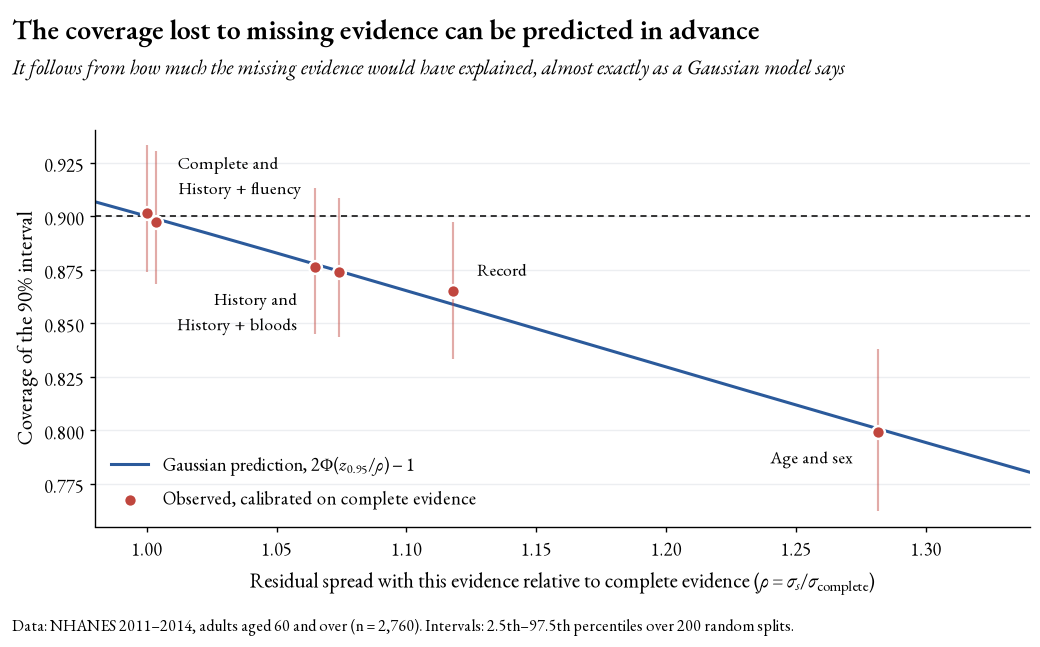

In [11]:
# Observed coverage under complete-case calibration against the Gaussian prediction
law = (cover[cover.scheme == "Complete-case"].groupby("state")
       .agg(sd_ratio=("sd_ratio", "mean"), observed=("coverage", "mean"),
            lo=("coverage", lambda s: s.quantile(0.025)), hi=("coverage", lambda s: s.quantile(0.975)))
       .reindex(NAMES))
z = stats.norm.ppf(1 - ALPHA / 2)
law["predicted"] = 2 * stats.norm.cdf(z / law.sd_ratio) - 1
display(law[["sd_ratio", "predicted", "observed"]].round(3))
print(f"Largest gap between predicted and observed coverage: {np.abs(law.predicted - law.observed).max():.3f}")

fig, ax = new_figure(6.0)
r = np.linspace(0.98, 1.36, 200)
ax.plot(r, 2 * stats.norm.cdf(z / r) - 1, color=NAVY, lw=2.0, zorder=2, label="Gaussian prediction, $2\\Phi(z_{0.95}/\\rho)-1$")
ax.axhline(1 - ALPHA, color=INK_3, lw=1.0, ls=(0, (4, 3)), zorder=1)
ax.vlines(law.sd_ratio, law.lo, law.hi, color=CRIMSON, lw=1.4, alpha=0.45, zorder=2)
ax.scatter(law.sd_ratio, law.observed, s=70, color=CRIMSON, edgecolor=PAPER, linewidth=1.6, zorder=3,
           label="Observed, calibrated on complete evidence")
for text, x, yy, ha, va in [("Complete and\nHistory + fluency", 1.012, 0.906, "left", "bottom"),
                            ("History and\nHistory + bloods", 1.058, 0.866, "right", "top"),
                            ("Record", 1.127, 0.869, "left", "bottom"), ("Age and sex", 1.272, 0.792, "right", "top")]:
    ax.text(x, yy, text, fontsize=11.5, color=INK_2, ha=ha, va=va, linespacing=1.1)
ax.set_xlim(0.98, 1.34)
ax.set_ylim(0.755, 0.94)
ax.grid(axis="y")
ax.set_xlabel("Residual spread with this evidence relative to complete evidence ($\\rho = \\sigma_s / \\sigma_{\\mathrm{complete}}$)")
ax.set_ylabel("Coverage of the 90% interval")
ax.legend(loc="lower left")
frame(fig, ax, "The coverage lost to missing evidence can be predicted in advance",
      "It follows from how much the missing evidence would have explained, almost exactly as a Gaussian model says",
      "Data: NHANES 2011–2014, adults aged 60 and over (n = 2,760). Intervals: 2.5th–97.5th percentiles over 200 random splits.",
      left=0.11)
save(fig, "04_coverage_loss_is_predictable.png")

### 5.4 People whose bloods are genuinely missing

Masking hides evidence at random. People who skip a blood draw are not a random subset, so the evidence-state intervals are checked on the 174 participants whose bloods are really missing. Coverage is averaged over each person's 200 evaluations, and the 95% interval resamples people.

In [12]:
# Coverage for participants whose blood markers are genuinely missing
def person_bootstrap(values, n_boot=2000, seed=0):
    rng_boot = np.random.default_rng(seed)
    means = [rng_boot.choice(values, len(values)).mean() for _ in range(n_boot)]
    return np.quantile(means, [0.025, 0.975])


rows = []
for s in ("History", "History + fluency"):
    per_person = real_hits[real_hits.state == s].groupby("row").hit.mean().to_numpy()
    lo, hi = person_bootstrap(per_person)
    rows.append({"state": s, "participants": len(per_person), "coverage": per_person.mean(), "2.5%": lo, "97.5%": hi})
real_table = pd.DataFrame(rows).set_index("state")
display(real_table.round(3))

,participants,coverage,2.5%,97.5%
state,,,,
History,174,0.892,0.848,0.934
History + fluency,174,0.906,0.862,0.945


### 5.5 What the next test would change

Forecasts are pooled over 60 splits. Two ways of simulating the missing result are compared: regression with resampled residuals (used in the figures) and borrowing the result of the 50 nearest neighbours in the history space.

In [13]:
# Triage before and after each test, forecasts against revealed results
undecided = value[value.before == "uncertain"].copy()
undecided["settled"] = (undecided.after != "uncertain").astype(float)
before_mix = value[value.test == "Fluency"].before.value_counts(normalize=True).rename("share on history alone")
display(before_mix.round(3).to_frame())

value_table = undecided.groupby("test").agg(
    forecast_regression=("p_regression", "mean"), forecast_neighbours=("p_neighbours", "mean"), observed=("settled", "mean"),
    brier_regression=("p_regression", lambda p: np.mean((p - undecided.loc[p.index, "settled"]) ** 2)),
    brier_neighbours=("p_neighbours", lambda p: np.mean((p - undecided.loc[p.index, "settled"]) ** 2)))
display(value_table.round(4))

ruled_out = undecided[undecided.after == "rule-out"]
miss = ruled_out.groupby("test").y.apply(lambda y: (y < THRESHOLD).mean()).rename("low performance among those newly ruled out")
display(miss.round(3).to_frame())
ruled_out_on_history = value[(value.test == "Fluency") & (value.before == "rule-out")]
print(f"Low performance among people ruled out on history alone: {(ruled_out_on_history.y < THRESHOLD).mean():.3f}")

,share on history alone
before,
uncertain,0.62
rule-out,0.38
flag,0.00


,forecast_regression,forecast_neighbours,observed,brier_regression,brier_neighbours
test,,,,,
Bloods,0.057,0.066,0.052,0.034,0.036
Fluency,0.133,0.155,0.123,0.084,0.088


,low performance among those newly ruled out
test,
Bloods,0.039
Fluency,0.033


Low performance among people ruled out on history alone: 0.026


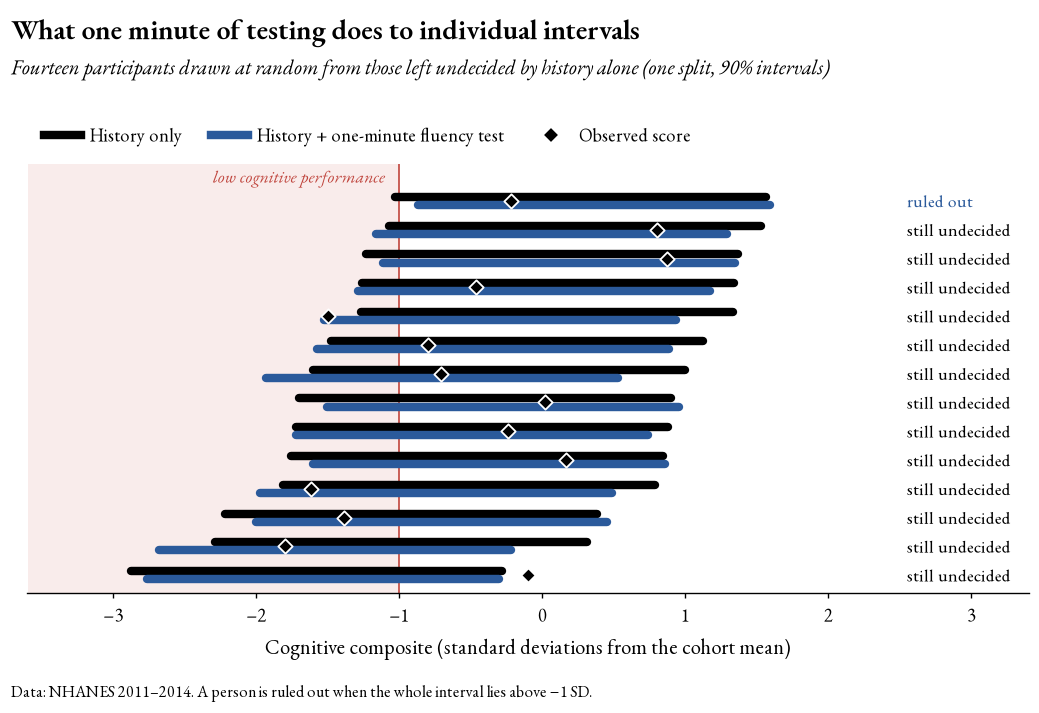

In [14]:
# Figure 5: fourteen randomly drawn undecided participants, before and after the fluency test
first = value[(value.rep == 0) & (value.test == "Fluency") & (value.before == "uncertain")]
pick = first.iloc[np.sort(np.random.default_rng(5).choice(len(first), 14, replace=False))]
pick = pick.assign(mid=(pick.lo_before + pick.hi_before) / 2).sort_values("mid", ascending=False)

fig, ax = new_figure(6.6)
y = np.arange(len(pick))
ax.axvspan(-3.6, THRESHOLD, color=CRIMSON_PALE, alpha=0.55, lw=0, zorder=0)
ax.axvline(THRESHOLD, color=CRIMSON, lw=1.1, zorder=1)
ax.hlines(y - 0.14, pick.lo_before, pick.hi_before, color=SLATE, lw=5.5, zorder=2, capstyle="round")
ax.hlines(y + 0.14, pick.lo_after, pick.hi_after, color=NAVY, lw=5.5, zorder=2, capstyle="round")
ax.scatter(pick.y, y, marker="D", s=44, color=INK, edgecolor=PAPER, linewidth=1.2, zorder=4)
for yy, after in zip(y, pick.after):
    ax.text(2.55, yy, {"rule-out": "ruled out", "uncertain": "still undecided", "flag": "flagged"}[after],
            va="center", ha="left", fontsize=11.5, color=NAVY if after == "rule-out" else INK_3)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlim(-3.6, 3.4)
ax.set_ylim(len(pick) - 0.4, -1.3)
ax.set_xlabel("Cognitive composite (standard deviations from the cohort mean)")
ax.text(THRESHOLD - 0.1, -0.85, "low cognitive performance", ha="right", va="center", fontsize=11.5, color=CRIMSON, style="italic")
ax.legend(handles=[Line2D([], [], color=SLATE, lw=5.5, label="History only"),
                   Line2D([], [], color=NAVY, lw=5.5, label="History + one-minute fluency test"),
                   Line2D([], [], marker="D", ls="", color=INK, markeredgecolor=PAPER, markersize=7, label="Observed score")],
          loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=3, columnspacing=1.6, handletextpad=0.5)
frame(fig, ax, "What one minute of testing does to individual intervals",
      "Fourteen participants drawn at random from those left undecided by history alone (one split, 90% intervals)",
      "Data: NHANES 2011–2014. A person is ruled out when the whole interval lies above −1 SD.", left=0.05, top_pad=1.55)
save(fig, "05_individual_intervals_before_and_after.png")

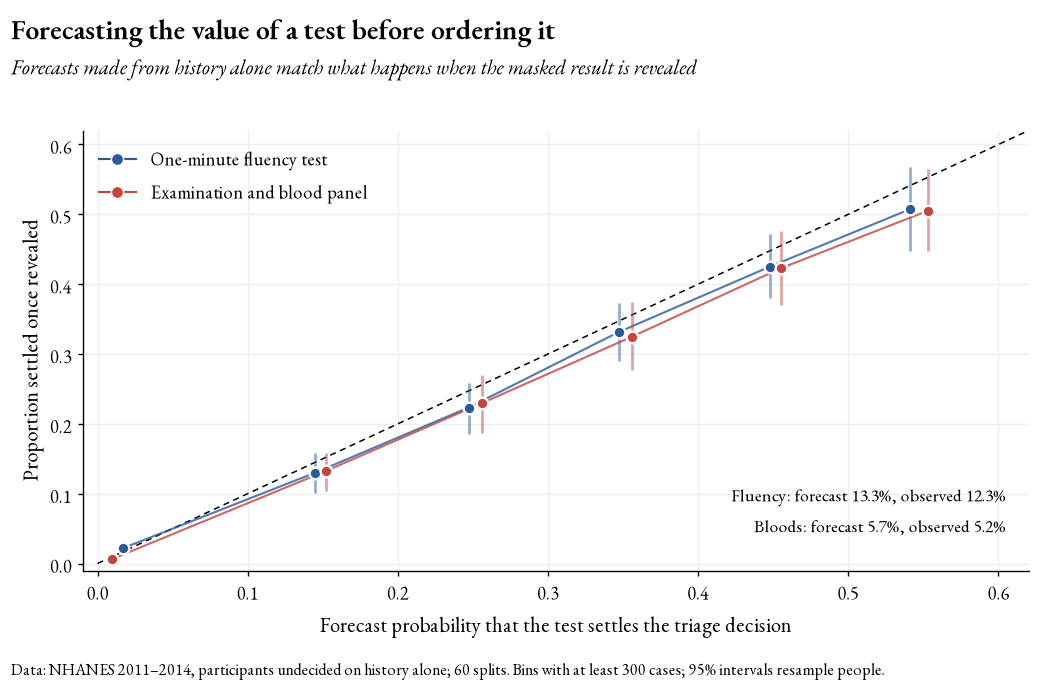

In [15]:
# Figure 6: reliability of the forecast value of each test, with intervals that resample people
edges = np.linspace(0, 1, 11)
rng_boot = np.random.default_rng(3)
fig, ax = new_figure(6.4)
ax.plot([0, 0.62], [0, 0.62], color=INK_3, lw=1.0, ls=(0, (4, 3)), zorder=1)
for test, colour, off in [("Fluency", NAVY, -0.004), ("Bloods", CRIMSON, 0.004)]:
    g = undecided[undecided.test == test].copy()
    g["bin"] = pd.cut(g.p_regression, edges, include_lowest=True, labels=False)
    by_person = g.groupby("row").indices
    people = np.array(list(by_person))
    agg = g.groupby("bin").agg(p=("p_regression", "mean"), o=("settled", "mean"), n=("settled", "size"))
    boots = []
    for _ in range(400):
        take = np.concatenate([by_person[r] for r in rng_boot.choice(people, len(people))])
        boots.append(g.iloc[take].groupby("bin").settled.mean())
    boots = pd.concat(boots, axis=1)
    agg["lo"], agg["hi"] = boots.quantile(0.025, axis=1), boots.quantile(0.975, axis=1)
    agg = agg[agg.n >= 300]
    ax.vlines(agg.p + off, agg.lo, agg.hi, color=colour, lw=1.8, alpha=0.5, zorder=2)
    ax.plot(agg.p + off, agg.o, color=colour, lw=1.4, alpha=0.8, zorder=2)
    ax.scatter(agg.p + off, agg.o, s=58, color=colour, edgecolor=PAPER, linewidth=1.5, zorder=3,
               label={"Fluency": "One-minute fluency test", "Bloods": "Examination and blood panel"}[test])
ax.set_xlim(-0.01, 0.62)
ax.set_ylim(-0.01, 0.62)
ax.grid(True)
ax.set_xlabel("Forecast probability that the test settles the triage decision")
ax.set_ylabel("Proportion settled once revealed")
ax.legend(handles=[series_handle(NAVY, "One-minute fluency test", lw=1.4), series_handle(CRIMSON, "Examination and blood panel", lw=1.4)],
          loc="upper left")
f, b = value_table.loc["Fluency"], value_table.loc["Bloods"]
ax.text(0.605, 0.03, f"Fluency: forecast {f.forecast_regression:.1%}, observed {f.observed:.1%}\n"
        f"Bloods: forecast {b.forecast_regression:.1%}, observed {b.observed:.1%}",
        ha="right", va="bottom", fontsize=11.5, color=INK_2, linespacing=1.3)
frame(fig, ax, "Forecasting the value of a test before ordering it",
      "Forecasts made from history alone match what happens when the masked result is revealed",
      "Data: NHANES 2011–2014, participants undecided on history alone; 60 splits. Bins with at least 300 cases; 95% intervals resample people.")
save(fig, "06_value_of_the_next_test.png")

### 5.6 Coverage across groups

Coverage of the history-only interval is averaged over each person's held-out appearances and then over the people in each group. The intervals resample people. With seventeen groups, one or two intervals that miss 0.90 would be expected by chance alone.

,group,level,n,coverage,2.5%,97.5%
0,Sex,Women,1404,0.897,0.882,0.911
1,Sex,Men,1356,0.905,0.891,0.919
2,Age,60–69,1496,0.908,0.893,0.921
3,Age,70–79,809,0.902,0.883,0.920
4,Age,80 and over,455,0.877,0.849,0.905
5,Education,Less than 9th grade,310,0.873,0.840,0.905
6,Education,9th–11th grade,378,0.885,0.853,0.914
7,Education,High school or GED,655,0.908,0.887,0.928
8,Education,Some college,776,0.919,0.900,0.937
9,Education,College graduate,639,0.895,0.871,0.917


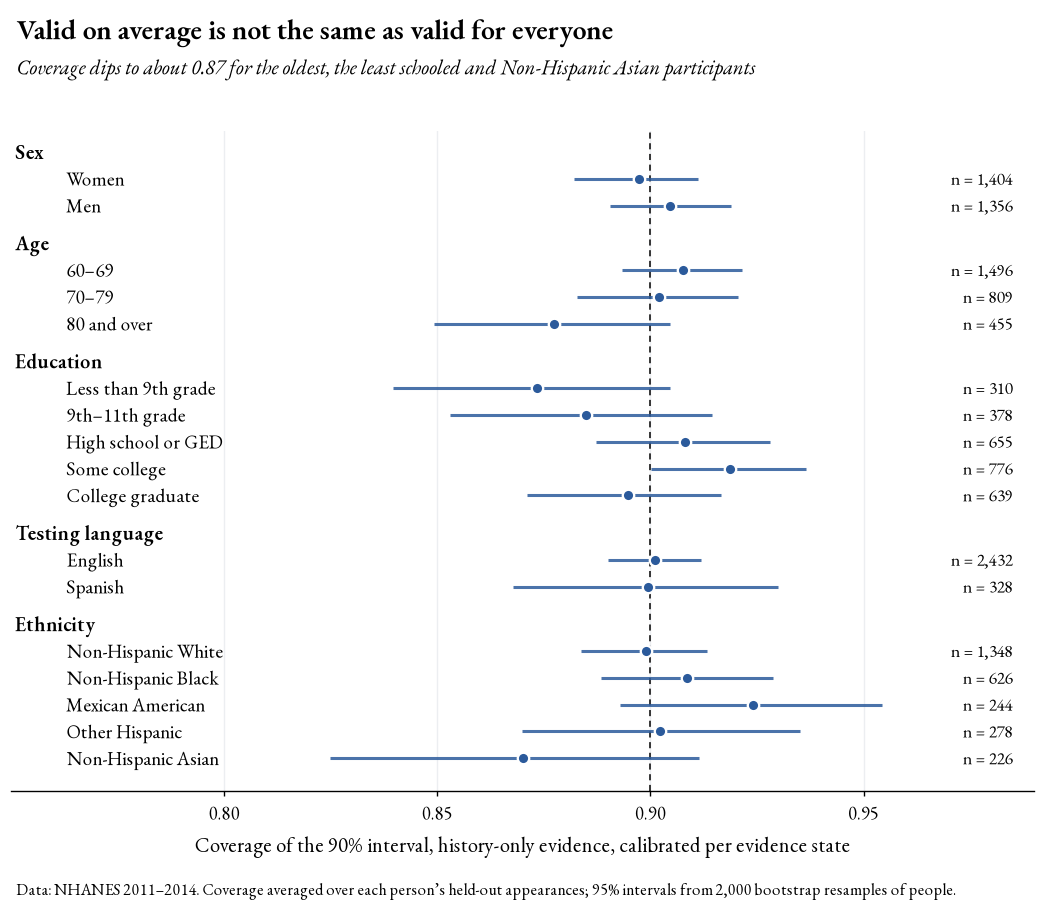

In [16]:
# Coverage by sex, age, education, testing language and ethnicity
hist_cov = person[person.state == "History"].groupby("row").hit.mean()
audit = main.loc[hist_cov.index].assign(coverage=hist_cov.to_numpy())
audit["age_band"] = pd.cut(audit.age, [59, 69, 79, 80], labels=["60–69", "70–79", "80 and over"]).astype(str)
EDUCATION = {1: "Less than 9th grade", 2: "9th–11th grade", 3: "High school or GED", 4: "Some college", 5: "College graduate"}
GROUPS = [
    ("Sex", audit.female.map({1.0: "Women", 0.0: "Men"}), ["Women", "Men"]),
    ("Age", audit.age_band, ["60–69", "70–79", "80 and over"]),
    ("Education", audit.education.map(EDUCATION), list(EDUCATION.values())),
    ("Testing language", audit.spanish_testing.map({0.0: "English", 1.0: "Spanish"}), ["English", "Spanish"]),
    ("Ethnicity", audit.ethnicity, ["Non-Hispanic White", "Non-Hispanic Black", "Mexican American", "Other Hispanic", "Non-Hispanic Asian"]),
]
rows = []
for group, column, levels in GROUPS:
    for level in levels:
        values = audit.loc[column == level, "coverage"].to_numpy()
        lo, hi = person_bootstrap(values, seed=1)
        rows.append({"group": group, "level": level, "n": len(values), "coverage": values.mean(), "2.5%": lo, "97.5%": hi})
group_table = pd.DataFrame(rows)
display(group_table.round(3))

fig, ax = new_figure(8.4)
ypos, heads, yy = [], [], 0
for group, _, levels in GROUPS:
    heads.append((yy, group))
    yy += 1
    for _ in levels:
        ypos.append(yy)
        yy += 1
    yy += 0.4
ax.axvline(1 - ALPHA, color=INK_3, lw=1.0, ls=(0, (4, 3)))
ax.hlines(ypos, group_table["2.5%"], group_table["97.5%"], color=NAVY, lw=2.0, alpha=0.85)
ax.scatter(group_table.coverage, ypos, s=56, color=NAVY, edgecolor=PAPER, linewidth=1.5, zorder=3)
for y0, group in heads:
    ax.text(0.751, y0, group, fontsize=13, fontweight="semibold", color=INK, va="center", ha="left")
for y0, (_, row) in zip(ypos, group_table.iterrows()):
    ax.text(0.763, y0, row.level, fontsize=12.5, color=INK_2, va="center", ha="left")
    ax.text(0.985, y0, f"n = {row.n:,}", fontsize=11, color=INK_3, va="center", ha="right")
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlim(0.75, 0.99)
ax.set_ylim(yy - 0.2, -0.8)
ax.set_xticks([0.80, 0.85, 0.90, 0.95])
ax.grid(axis="x")
ax.set_xlabel("Coverage of the 90% interval, history-only evidence, calibrated per evidence state")
frame(fig, ax, "Valid on average is not the same as valid for everyone",
      "Coverage dips to about 0.87 for the oldest, the least schooled and Non-Hispanic Asian participants",
      "Data: NHANES 2011–2014. Coverage averaged over each person’s held-out appearances; 95% intervals from 2,000 bootstrap resamples of people.",
      left=0.03)
save(fig, "07_coverage_across_groups.png")

### 5.7 Robustness checks

Two checks. First, conformalised quantile regression (CQR; Romano et al., 2019), whose base models learn a separate spread under each evidence state. Second, coverage reweighted with the NHANES examination weights, so that it refers to the US population aged 60 and over rather than to the sample.

In [17]:
# Conformalised quantile regression under complete-case and evidence-state calibration
cqr_table = cqr.groupby(["state", "scheme"]).agg(coverage=("coverage", "mean"), width=("width", "mean")).unstack("scheme").reindex(NAMES)
display(cqr_table.round(3))

# Coverage reweighted to the US population with the examination weights
weighted = []
for s in ("History", "Complete"):
    per_person = person[person.state == s].groupby("row").hit.mean()
    w = main.loc[per_person.index, "mec_weight"].to_numpy()
    weighted.append({"state": s, "unweighted": per_person.mean(), "survey-weighted": np.average(per_person, weights=w)})
display(pd.DataFrame(weighted).set_index("state").round(3))

coverage                        width               
scheme            Complete-case Evidence-state Complete-case Evidence-state
state                                                                      
Age and sex               0.920          0.901         3.206          3.039
Record                    0.916          0.902         2.789          2.668
History                   0.907          0.902         2.653          2.608
History + bloods          0.901          0.902         2.596          2.598
History + fluency         0.908          0.901         2.486          2.435
Complete                  0.902          0.902         2.446          2.446

,unweighted,survey-weighted
state,,
History,0.901,0.904
Complete,0.901,0.908


## 6. Summary

In [18]:
# Numbers quoted in the README
report = {
    "main cohort": len(main),
    "bloods genuinely missing": len(real),
    "R2 ridge, history": perf.query("model == 'Ridge regression' and state == 'History'").r2.mean(),
    "R2 ridge, history + bloods": perf.query("model == 'Ridge regression' and state == 'History + bloods'").r2.mean(),
    "R2 ridge, history + fluency": perf.query("model == 'Ridge regression' and state == 'History + fluency'").r2.mean(),
    "R2 ridge, complete": perf.query("model == 'Ridge regression' and state == 'Complete'").r2.mean(),
    "coverage, complete-case, history": law.loc["History", "observed"],
    "coverage, complete-case, age and sex": law.loc["Age and sex", "observed"],
    "coverage, evidence-state, lowest state": cover.query("scheme == 'Evidence-state'").groupby("state").coverage.mean().min(),
    "coverage, evidence-state, highest state": cover.query("scheme == 'Evidence-state'").groupby("state").coverage.mean().max(),
    "largest gap to Gaussian prediction": np.abs(law.predicted - law.observed).max(),
    "coverage, bloods genuinely missing (history)": real_table.loc["History", "coverage"],
    "undecided on history alone": before_mix.get("uncertain", 0.0),
    "settled by fluency, forecast": f.forecast_regression,
    "settled by fluency, observed": f.observed,
    "settled by bloods, forecast": b.forecast_regression,
    "settled by bloods, observed": b.observed,
}
pd.Series({k: f"{v:,}" if isinstance(v, int) else f"{float(v):.3f}" for k, v in report.items()}, name="value").to_frame()

,value
main cohort,"2,760"
bloods genuinely missing,174
"R2 ridge, history",0.399
"R2 ridge, history + bloods",0.408
"R2 ridge, history + fluency",0.476
"R2 ridge, complete",0.479
"coverage, complete-case, history",0.874
"coverage, complete-case, age and sex",0.799
"coverage, evidence-state, lowest state",0.901
"coverage, evidence-state, highest state",0.902
